## PPG Peak Detection
This notebook detects heartbeats directly from the PPG Green signal, using the pipeline from Source 1, and uses them to make two outputs for `999_hrv-cleaning.ipynb`: a table of beats and a mask that flags 10-second windows into one of two quality-control categories:
- Acceptable -> The detected peaks in this window pass all of the PPG quality checks below.
- Unacceptable -> At least one check fails, so the peaks in this window are likely missed, extra, or not a clean pulse.

There is no Shaky category. The checks from the source are pass/fail and the paper gives no margin around its thresholds, so adding one would be inventing a threshold.

This replaces `discarded/003_IBI-filtering.ipynb`, which applied the checks to the EmotiBit's own detected beats (`BI`).

### Files Used
- `data-files\2.1_G1_ground_truth_PG.csv` -> PPG Green. The signal the beats are detected from.
- `data-files\2.1_G1_ground_truth_PI.csv`, `data-files\2.1_G1_ground_truth_PR.csv` -> PPG Infrared and Red. Only used for cross-checks.
- `data-files\2.1_G1_ground_truth_BI.csv` -> The device's own beat intervals. Only used for cross-checks.
- `data-files\2.1_G1_biometrics.csv` -> Contains phase markers
- `processed-data\2.1_G1_movement_mask.csv` -> Movement mask from `001_movement-artifacts.ipynb`, used only for a cross-check

### Important Notes On Measurement Variables
- PPG Green has shallow penetration depth. Its primary use is for heart rate and HRV data. It is also less prone to movement artifacts. PPG Green, along with Polar ECG measurements in the future, should be our main HRV metrics.
- PPG Red has moderate penetration depth. More susceptible to ambient light interference and movement artifacts. It's most commonly used on patients who are remaining completely still. However, if the participant is sitting still and only doing a minor task like typing or talking, we can use this with caution.
- PPG Infrared has deep penetration depth. It is also significantly less affected by skin tone. However, it can pick up noise from deeper tissues like muscle fibers and is also susceptible to movement artifacts. It's most commonly used on patients who are remaining completely still. However, if the participant is sitting still and only doing a minor task like typing or talking, we can use this with caution.

### Sources I'm Using To Determine The Pipeline & QC Thresholds

#### Source 1
Vorreuther, Tagalidou & Vukelić (2025), *Validation of the EmotiBit wearable sensor for heart-based measures under varying workload conditions*. `https://pmc.ncbi.nlm.nih.gov/articles/PMC12213893/` \
They compared EmotiBit PPG to a reference ECG in 15 people. Their best PPG pipeline was Langevin et al. (2021) cleaning (band-pass 0.7–3.5 Hz) followed by Elgendi et al. (2013) peak detection, run in NeuroKit. They then split the recording into 10-second windows and used the following checks:

| Quality check | Threshold used in the paper | What it means |
|---|---|---|
| Physiologically plausible heart rate | 30–180 BPM | Reject windows producing implausible heart-rate estimates. |
| Maximum gap between successive pulse peaks | ≤ 3 seconds | Reject windows with gaps long enough to mean more than one beat was missed. |
| Beat-to-beat interval ratio | < 2.2 | The largest interval divided by the smallest must be less than 2.2. |
| PPG signal similarity | Correlation coefficient ≥ 0.86 | The pulse waves must resemble the window's average pulse wave. |

The paper's results matter for how these beats can be used. Against ECG, PPG heart rate agreed excellently (Bland-Altman ratio ≤ 0.01), the SD of intervals moderately (0.17–0.19), and RMSSD insufficiently (0.29–0.36, where above 0.2 is insufficient). RMSSD failed even though 89.5% of its PPG windows passed the checks.

The paper also says heart rate shouldn't change more than 10% within a window. This is treated as the reason for the 2.2 limit (2 × 1.1, one missed beat plus 10%), not as a separate check. The paper doesn't state this directly.

### Assumptions
1. **PPG Green is used alone, although the paper averaged all three wavelengths.** The paper itself says green is best suited to HRV, and it is this project's main HRV channel. The 0.86 threshold was set on the averaged signal, so it may not carry over exactly. "Cross-Check 5" shows how much the choice matters.
2. **The signal is linearly interpolated onto an even 100 Hz grid.** NeuroKit assumes evenly spaced samples. The real rate is 99.57 Hz, so treating the samples as exactly 100 Hz would drift by 22 s by the end of the session ("Loading PPG & Checking Timing"). Peak times therefore have 10 ms resolution, the same as the device's `BI`.
3. **NeuroKit's `langevin2021` method is the paper's cleaning step.** NeuroKit's documentation for this method cites this paper. It uses a second-order Butterworth filter. The text of the paper that I could read doesn't state the order. This notebook uses NeuroKit 0.3.0, and the paper used 0.2.10.
4. **NeuroKit's artifact correction is off.** The paper doesn't describe any, and correcting peaks before the checks would hide the failures the checks are meant to catch.
5. **Each interval ends at its beat's timestamp.** This matches how `BI` rows work. The first peak has no interval, so 6333 peaks give 6332 beats.
6. **Windows are built the same way as in the discarded `003`.** They run back to back from the first PPG sample, the last is shorter than 10 s, and each is labelled with the phase at its start. A window's intervals include every interval that overlaps it. Heart rate is 60 / mean interval, because the paper doesn't say how its estimate was made.
7. **Template correlation is calculated per window, on the cleaned signal.** Following the paper's description, each pulse wave is a slice as wide as the window's median interval, the template is the mean of those waves, and the result is the mean correlation of each wave with the template. Two details aren't in the text I could read, so these are my choices: waves are centred on their peak, and they are cut from the full signal so that a peak near a window's edge still gets a full wave. A window with fewer than 2 usable waves fails. Only peaks inside the window are used here, unlike the other three checks, which also include the interval running across the window's end (Assumption 6), because a pulse wave belongs to the window its peak is in. This is written from the paper's description rather than using `nk.ppg_quality`, because NeuroKit describes that function as only loosely based on the original method (Orphanidou et al., 2015), and it gives a continuous score rather than one value per window. The discarded `003` left this check out. It is included here because this notebook follows the paper's method, and each check keeps its own column, so the result without it can still be calculated.
8. **Derived beats are estimates, not ground truth.** Case Study 1 has no ECG, so nothing here can prove a beat is correct. The cross-checks can only show which beats are more plausible.

### Important Data Processing Steps To Note
**1. PPG Green is resampled, cleaned and searched for peaks.** *(Code: "Resampling, Cleaning & Peak Detection" section.)*

**2. Beats are built from the peaks.** *(Code: "Building The Beat Table" section.)*
- `PPI` (peak-to-peak interval, ms) is used as the name rather than `BI`, because `BI` in this project means the device's value.

**3. The recording is cut into 10 s windows, and the four checks are run on each.** *(Code: "Running The Checks" section.)*
- Acceptable if all four pass, otherwise Unacceptable. Each check's result is kept as its own column.

**4. The result is cross-checked six ways.** *(Code: "Cross-Check" sections.)*
- Against the device's beats, a heart rate estimate with no peak detection, the waveform by eye, other wavelengths and cleaning settings, signals with no heartbeat in them, and RMSSD agreement between sources.

**5. Phases are attached from the biometrics file.** *(Code: "Attaching Experiment Phases" section.)*

**6. Outputs: one row per beat, and one row per window.** *(Code: "Beat Table & Mask Outputs" section.)*
- Saved to `processed-data/2.1_G1_ppg_beats.csv` and `processed-data/2.1_G1_ppg_peak_mask.csv` for use in `999_hrv-cleaning.ipynb`.

### Global Variables & Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk

print(f"NeuroKit version: {nk.__version__} (the paper used 0.2.10)")

DATA_DIR = Path("../data-files")
PROCESSED_DIR = Path("../processed-data")
PG_FILE = DATA_DIR / "2.1_G1_ground_truth_PG.csv"
PI_FILE = DATA_DIR / "2.1_G1_ground_truth_PI.csv"
PR_FILE = DATA_DIR / "2.1_G1_ground_truth_PR.csv"
BI_FILE = DATA_DIR / "2.1_G1_ground_truth_BI.csv"
BIOMETRICS_FILE = DATA_DIR / "2.1_G1_biometrics.csv"
MOVEMENT_MASK_FILE = PROCESSED_DIR / "2.1_G1_movement_mask.csv"
BEATS_OUTPUT_FILE = PROCESSED_DIR / "2.1_G1_ppg_beats.csv"
MASK_OUTPUT_FILE = PROCESSED_DIR / "2.1_G1_ppg_peak_mask.csv"

# Pipeline from Source 1
SAMPLING_RATE_HZ = 100
CLEAN_METHOD = "langevin2021" # Band-pass 0.7-3.5 Hz
PEAK_METHOD = "elgendi"

# Thresholds from Source 1
WINDOW_S = 10
HR_MIN_BPM = 30
HR_MAX_BPM = 180
MAX_GAP_S = 3 # Largest interval allowed (pass if <=)
MAX_INTERVAL_RATIO = 2.2 # Largest / smallest interval (pass if <)
MIN_TEMPLATE_CORR = 0.86 # Average correlation with the template (pass if >=)

CHECKS = ["hr_ok", "gap_ok", "ratio_ok", "template_ok"]
QUALITY_ORDER = ["Acceptable", "Unacceptable"]
QUALITY_COLORS = {"Acceptable": "#0ca30c", "Unacceptable": "#d03b3b"}
DERIVED_COLOR, DEVICE_COLOR, SIGNAL_COLOR = "#2a78d6", "#eb6834", "#52514e"

NeuroKit version: 0.3.0 (the paper used 0.2.10)


### Loading PPG & Checking Timing
NeuroKit assumes evenly spaced samples, so this checks whether `LocalTimestamp` is evenly spaced, whether it has gaps, and whether the real rate is exactly 100 Hz (Assumption 2).

In [2]:
green = pd.read_csv(PG_FILE, usecols=["LocalTimestamp", "EmotiBitTimestamp", "DataReliability", "PG"])
step_ms = green["LocalTimestamp"].diff() * 1000
duration_s = green["LocalTimestamp"].iloc[-1] - green["LocalTimestamp"].iloc[0]
real_rate = (len(green) - 1) / duration_s

print(f"Samples: {len(green)}, duration {duration_s / 60:.2f} min, missing values {green['PG'].isna().sum()}")
print(f"DataReliability values: {green['DataReliability'].value_counts().to_dict()}")
print(f"Sorted: {green['LocalTimestamp'].is_monotonic_increasing}, repeated timestamps: {(step_ms == 0).sum()}")
print(f"Step between samples (ms): median {step_ms.median():.2f}, min {step_ms.min():.2f}, max {step_ms.max():.2f}")
print(f"Real sampling rate: {real_rate:.2f} Hz")
print(f"Drift by the end if this were treated as exactly 100 Hz: {duration_s - (len(green) - 1) / SAMPLING_RATE_HZ:.1f} s")

Samples: 506648, duration 84.81 min, missing values 0
DataReliability values: {100: 506648}
Sorted: True, repeated timestamps: 3
Step between samples (ms): median 9.73, min 0.00, max 10.91
Real sampling rate: 99.57 Hz
Drift by the end if this were treated as exactly 100 Hz: 22.0 s


### Resampling, Cleaning & Peak Detection
The steps follow the paper's chosen PPG pipeline:
1. Resample to an even 100 Hz grid on `LocalTimestamp` (Assumption 2).
2. Clean with NeuroKit's `langevin2021` method.
3. Detect systolic peaks with NeuroKit's `elgendi` method. Artifact correction stays off (Assumption 4).

`detect_beats` is a function because the cross-checks below run the same steps on the other wavelengths.

In [3]:
recording_start, recording_end = green["LocalTimestamp"].iloc[0], green["LocalTimestamp"].iloc[-1]
grid_t = np.arange(recording_start, recording_end, 1 / SAMPLING_RATE_HZ)

def detect_beats(raw_values, raw_times, clean_method=CLEAN_METHOD):
    """Returns the cleaned 100 Hz signal, and the peaks as sample positions on grid_t."""
    resampled = np.interp(grid_t, raw_times, raw_values.astype(float))
    cleaned = np.asarray(nk.ppg_clean(resampled, sampling_rate=SAMPLING_RATE_HZ, method=clean_method))
    _, info = nk.ppg_peaks(cleaned, sampling_rate=SAMPLING_RATE_HZ, method=PEAK_METHOD, correct_artifacts=False)
    return cleaned, np.asarray(info["PPG_Peaks"])

clean, peaks = detect_beats(green["PG"].to_numpy(), green["LocalTimestamp"].to_numpy())
peak_t = grid_t[peaks]
print(f"Peaks detected: {len(peaks)}, average rate {60 * len(peaks) / duration_s:.1f} BPM")

Peaks detected: 6333, average rate 74.7 BPM


### Building The Beat Table
Each beat's interval is the time from the previous peak to this peak, the paper's PP-interval (Assumption 5). The first peak has no previous peak, so it has no row. `PPI` is in ms, like the device's `BI`. `EmotiBitTimestamp` is read off the PPG file's own timestamp pairs so the table has both clocks.

In [4]:
ppg_beats = pd.DataFrame({
    "LocalTimestamp": peak_t[1:],
    "EmotiBitTimestamp": np.interp(peak_t[1:], green["LocalTimestamp"], green["EmotiBitTimestamp"]).round(1),
    "PPI": np.round(np.diff(peak_t) * 1000, 0),
})
print(ppg_beats["PPI"].describe(percentiles=[.01, .05, .5, .95, .99]).round(0).to_string())

device = pd.read_csv(BI_FILE, usecols=["LocalTimestamp", "BI"])
print(f"\nDevice beats (BI file): {len(device)}. Derived beats: {len(ppg_beats)}")
print(f"Intervals over 1.5 s: device {100 * (device['BI'] > 1500).mean():.1f}%, derived {100 * (ppg_beats['PPI'] > 1500).mean():.1f}%")
print(f"Intervals under 0.5 s: device {100 * (device['BI'] < 500).mean():.1f}%, derived {100 * (ppg_beats['PPI'] < 500).mean():.1f}%")
ppg_beats.head()

count    6332.0
mean      804.0
std       111.0
min       310.0
1%        510.0
5%        630.0
50%       800.0
95%       980.0
99%      1040.0
max      1660.0

Device beats (BI file): 5041. Derived beats: 6332
Intervals over 1.5 s: device 9.6%, derived 0.0%
Intervals under 0.5 s: device 1.4%, derived 0.9%


,LocalTimestamp,EmotiBitTimestamp,PPI
0,1.757035e+09,2101202.0,1480.0
1,1.757035e+09,2101642.0,440.0
2,1.757035e+09,2102412.0,770.0
3,1.757035e+09,2103291.9,880.0
4,1.757035e+09,2103931.9,640.0


### Running The Checks
The recording is cut into back-to-back 10 s windows, starting at the first PPG sample (Assumption 6). For each window:
- `hr_bpm` = 60 / mean interval. `hr_ok` if 30 ≤ `hr_bpm` ≤ 180.
- `max_gap_s` = largest interval. `gap_ok` if ≤ 3 s.
- `interval_ratio` = largest / smallest interval. `ratio_ok` if < 2.2.
- `template_corr` = the average correlation of each pulse wave with the window's average wave (Assumption 7). `template_ok` if ≥ 0.86.

A window is Acceptable only if all four pass. A window's intervals are every interval that overlaps it, including the one running across its end (Assumption 6).

`interval_checks` is a function so that the device's beats can go through exactly the same checks.

In [5]:
window_starts = np.arange(recording_start, recording_end, WINDOW_S)
windows = pd.DataFrame({"window_start": window_starts, "window_end": np.minimum(window_starts + WINDOW_S, recording_end)})

def interval_checks(windows, beat_t, interval_s):
    """Heart rate, gap and ratio values per window, from beat times and the interval ending at each beat."""
    first = np.searchsorted(beat_t, windows["window_start"], side="left")
    closing = np.searchsorted(beat_t, windows["window_end"], side="left")
    last = np.minimum(closing, len(beat_t) - 1)
    intervals = [interval_s[a:b + 1] for a, b in zip(first, last)]
    result = pd.DataFrame({
        "beats_in_window": closing - first,
        "hr_bpm": [60 / x.mean() for x in intervals],
        "max_gap_s": [x.max() for x in intervals],
        "interval_ratio": [x.max() / x.min() for x in intervals],
    }, index=windows.index)
    result["hr_ok"] = result["hr_bpm"].between(HR_MIN_BPM, HR_MAX_BPM)
    result["gap_ok"] = result["max_gap_s"] <= MAX_GAP_S
    result["ratio_ok"] = result["interval_ratio"] < MAX_INTERVAL_RATIO
    return result

def template_correlation(signal, window_peaks):
    """Average correlation of each pulse wave with the mean wave, as Source 1 describes (Assumption 7)."""
    if len(window_peaks) < 2:
        return np.nan
    width = int(round(np.median(np.diff(window_peaks))))
    starts = window_peaks - width // 2
    starts = starts[(starts >= 0) & (starts + width <= len(signal))]
    if len(starts) < 2:
        return np.nan
    waves = np.array([signal[s:s + width] for s in starts])
    template = waves.mean(axis=0)
    return np.mean([np.corrcoef(wave, template)[0, 1] for wave in waves])

def template_checks(windows, signal, peak_positions):
    peak_times = grid_t[peak_positions]
    first = np.searchsorted(peak_times, windows["window_start"], side="left")
    end = np.searchsorted(peak_times, windows["window_end"], side="left")
    return np.array([template_correlation(signal, peak_positions[a:b]) for a, b in zip(first, end)])

windows = windows.join(interval_checks(windows, peak_t[1:], np.diff(peak_t)))
windows["template_corr"] = template_checks(windows, clean, peaks)
windows["template_ok"] = windows["template_corr"] >= MIN_TEMPLATE_CORR
windows["quality"] = pd.Categorical(
    np.where(windows[CHECKS].all(axis=1), "Acceptable", "Unacceptable"), categories=QUALITY_ORDER
)

counts = windows["quality"].value_counts().reindex(QUALITY_ORDER).to_frame("windows")
counts["pct"] = (100 * counts["windows"] / counts["windows"].sum()).round(1)
print(counts.to_string())
print(f"\nPassing the first three checks only: {100 * windows[CHECKS[:3]].all(axis=1).mean():.1f}%")
print("Share of windows failing each check:", {c: round(100 * (~windows[c]).mean(), 1) for c in CHECKS})

failing = windows[windows["quality"] == "Unacceptable"]
print("\nUnacceptable windows by which checks fail:")
failing[CHECKS].eq(False).apply(
    lambda r: " + ".join(c.replace("_ok", "") for c, failed in zip(CHECKS, r) if failed), axis=1
).value_counts().to_frame("windows")

              windows   pct
quality                    
Acceptable        463  91.0
Unacceptable       46   9.0

Passing the first three checks only: 93.1%
Share of windows failing each check: {'hr_ok': np.float64(0.0), 'gap_ok': np.float64(0.0), 'ratio_ok': np.float64(6.9), 'template_ok': np.float64(7.5)}

Unacceptable windows by which checks fail:


,windows
ratio + template,27
template,11
ratio,8


How far the failing windows are from the thresholds. If most are only just over a threshold, the result depends on the exact value chosen.

In [6]:
for ratio in [2.0, 2.2, 2.5, 3.0]:
    for corr in [0.80, 0.86, 0.90]:
        passed = windows["hr_ok"] & windows["gap_ok"] & (windows["interval_ratio"] < ratio) & (windows["template_corr"] >= corr)
        print(f"ratio < {ratio}, template >= {corr}: {100 * passed.mean():.1f}% Acceptable")

pd.DataFrame({
    "interval_ratio (when ratio fails)": windows.loc[~windows["ratio_ok"], "interval_ratio"].describe(),
    "template_corr (when template fails)": windows.loc[~windows["template_ok"], "template_corr"].describe(),
    "interval_ratio (Acceptable)": windows.loc[windows["quality"] == "Acceptable", "interval_ratio"].describe(),
    "template_corr (Acceptable)": windows.loc[windows["quality"] == "Acceptable", "template_corr"].describe(),
}).round(2)

ratio < 2.0, template >= 0.8: 92.1% Acceptable
ratio < 2.0, template >= 0.86: 90.4% Acceptable
ratio < 2.0, template >= 0.9: 81.7% Acceptable
ratio < 2.2, template >= 0.8: 92.7% Acceptable
ratio < 2.2, template >= 0.86: 91.0% Acceptable
ratio < 2.2, template >= 0.9: 82.1% Acceptable
ratio < 2.5, template >= 0.8: 94.1% Acceptable
ratio < 2.5, template >= 0.86: 91.7% Acceptable
ratio < 2.5, template >= 0.9: 82.7% Acceptable
ratio < 3.0, template >= 0.8: 96.1% Acceptable
ratio < 3.0, template >= 0.86: 92.3% Acceptable
ratio < 3.0, template >= 0.9: 82.7% Acceptable


,interval_ratio (when ratio fails),template_corr (when template fails),interval_ratio (Acceptable),template_corr (Acceptable)
count,35.00,38.00,463.00,463.00
mean,2.88,0.80,1.38,0.94
std,0.51,0.04,0.17,0.03
min,2.25,0.68,1.09,0.86
25%,2.55,0.77,1.26,0.93
50%,2.79,0.80,1.35,0.95
75%,3.05,0.83,1.45,0.96
max,4.48,0.86,2.17,0.98


### Cross-Check 1: Device Beats Through The Same Checks
The paper's checks were written for peaks detected offline, so this shows what they give on the device's `BI` values, using the same windows and code. Template correlation needs a peak detected on the waveform, so it is only applied to derived peaks.

In [7]:
device_checks = interval_checks(windows[["window_start", "window_end"]], device["LocalTimestamp"].to_numpy(), device["BI"].to_numpy() / 1000)
windows["device_pass"] = device_checks[["hr_ok", "gap_ok", "ratio_ok"]].all(axis=1)
windows["device_hr_bpm"] = device_checks["hr_bpm"]

print(f"Windows passing heart rate, gap and ratio: device {100 * windows['device_pass'].mean():.1f}%, "
      f"derived {100 * windows[CHECKS[:3]].all(axis=1).mean():.1f}%")
pd.crosstab(windows["device_pass"].rename("device passes 3 checks"), windows["quality"].rename("derived (4 checks)"), margins=True)

Windows passing heart rate, gap and ratio: device 31.4%, derived 93.1%


derived (4 checks),Acceptable,Unacceptable,All
device passes 3 checks,,,
False,304,45,349
True,159,1,160
All,463,46,509


### Cross-Check 2: Heart Rate Without Any Peak Detection
Passing the checks doesn't prove that peaks are correct. A detector that double-counted steadily could still pass. So each window's heart rate is also estimated from the strongest frequency in the cleaned signal, which doesn't use any detected peak. It is still the same green signal, so this tests the peak detection, not the signal itself. Windows shorter than 5 s are skipped.

In [8]:
def spectral_hr(signal, start, end):
    a, b = np.searchsorted(grid_t, [start, end])
    segment = signal[a:b]
    if len(segment) < 5 * SAMPLING_RATE_HZ:
        return np.nan
    power = np.abs(np.fft.rfft(segment * np.hanning(len(segment)), 8192))
    freqs = np.fft.rfftfreq(8192, 1 / SAMPLING_RATE_HZ)
    band = (freqs >= 0.7) & (freqs <= 3.5)
    return 60 * freqs[band][np.argmax(power[band])]

windows["spectral_hr_bpm"] = [spectral_hr(clean, s, e) for s, e in zip(windows["window_start"], windows["window_end"])]

rows = []
for label, column in [("Derived peaks", "hr_bpm"), ("Device BI", "device_hr_bpm")]:
    diff = (windows[column] - windows["spectral_hr_bpm"]).dropna()
    rows.append({
        "beats": label, "median_hr_bpm": windows[column].median(), "median_abs_diff_bpm": diff.abs().median(),
        "pct_within_5_bpm": 100 * (diff.abs() <= 5).mean(),
        "pct_over_10_bpm_low": 100 * (diff < -10).mean(), "pct_over_10_bpm_high": 100 * (diff > 10).mean(),
    })
print(f"Spectral median HR: {windows['spectral_hr_bpm'].median():.1f} BPM")
acceptable = windows["quality"] == "Acceptable"
acceptable_diff = (windows["hr_bpm"] - windows["spectral_hr_bpm"])[acceptable].dropna()
print(f"Derived peaks, Acceptable windows only: {100 * (acceptable_diff.abs() <= 5).mean():.1f}% within 5 BPM")
pd.DataFrame(rows).round(1)

Spectral median HR: 74.0 BPM
Derived peaks, Acceptable windows only: 86.0% within 5 BPM


,beats,median_hr_bpm,median_abs_diff_bpm,pct_within_5_bpm,pct_over_10_bpm_low,pct_over_10_bpm_high
0,Derived peaks,74.4,2.1,83.7,0.8,0.8
1,Device BI,63.8,8.1,37.5,45.8,0.0


Heart rate per window from the derived and device beats. The device's estimate should sit on top of the derived one if the two agree.

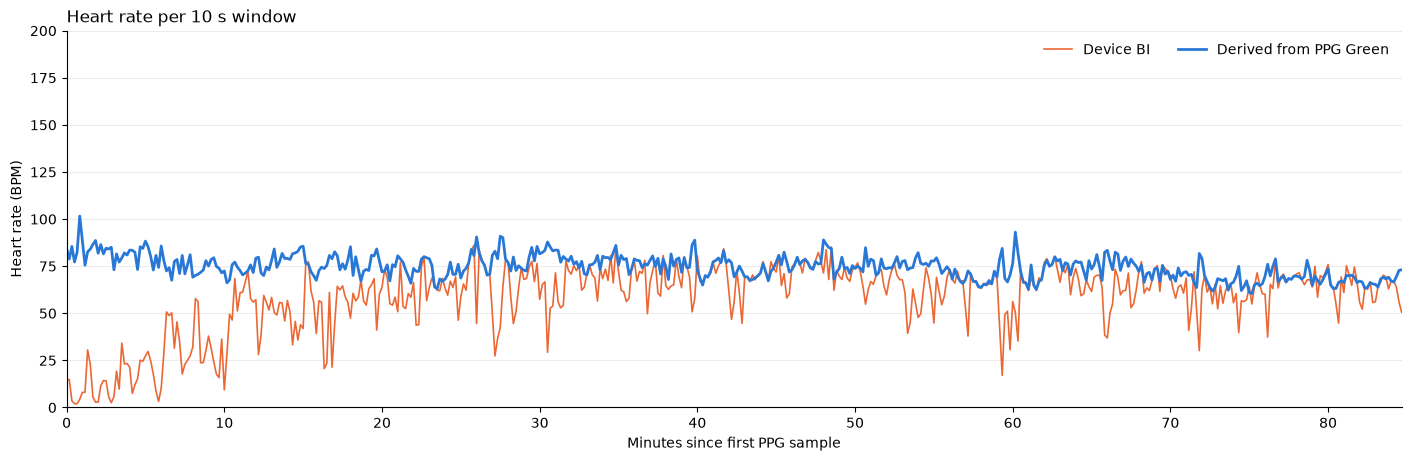

In [9]:
windows["minutes"] = (windows["window_start"] - recording_start) / 60
HR_PLOT_MAX = 200

fig, ax = plt.subplots(figsize=(14, 4.5), constrained_layout=True)
ax.plot(windows["minutes"], windows["device_hr_bpm"].clip(upper=HR_PLOT_MAX), color=DEVICE_COLOR, lw=1.2, label="Device BI")
ax.plot(windows["minutes"], windows["hr_bpm"].clip(upper=HR_PLOT_MAX), color=DERIVED_COLOR, lw=2, label="Derived from PPG Green")
ax.set_xlim(0, windows["minutes"].max())
ax.set_ylim(0, HR_PLOT_MAX)
ax.set_xlabel("Minutes since first PPG sample")
ax.set_ylabel("Heart rate (BPM)")
ax.set_title("Heart rate per 10 s window", loc="left")
ax.grid(axis="y", color="#000000", alpha=0.08)
ax.legend(loc="upper right", frameon=False, ncol=2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

### Cross-Check 3: Inspecting The Waveform
Two 20 s stretches of the cleaned signal, with derived peaks and device beats marked. The top stretch is the longest run of Unacceptable windows early in the session, and the bottom is from a run of Acceptable windows where the device also passes. Device beats are drawn at their own timestamps. Their offset from the peaks is measured in Cross-Check 4.

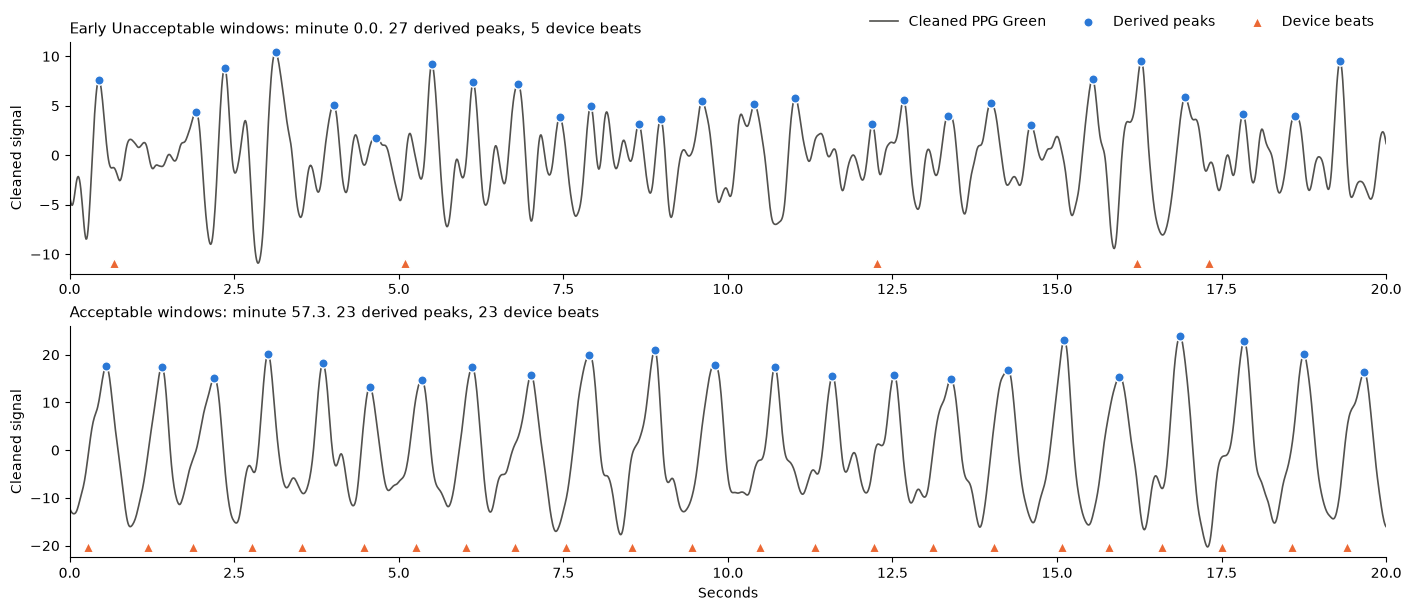

In [10]:
def run_starts(mask):
    change = mask.ne(mask.shift()).cumsum()
    return mask[mask].groupby(change[mask]).apply(lambda r: (len(r), r.index[0]))

bad = (windows["quality"] == "Unacceptable") & (windows["minutes"] < 20)
good = (windows["quality"] == "Acceptable") & windows["device_pass"]
examples = [
    ("Early Unacceptable windows", windows.loc[run_starts(bad).max()[1], "window_start"]),
    ("Acceptable windows", windows.loc[run_starts(good).max()[1], "window_start"]),
]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), constrained_layout=True)
for ax, (title, start) in zip(axes, examples):
    end = start + 20
    a, b = np.searchsorted(grid_t, [start, end])
    p = peaks[(peaks >= a) & (peaks < b)]
    d = device["LocalTimestamp"].to_numpy()
    d = d[(d >= start) & (d < end)]
    ax.plot(grid_t[a:b] - start, clean[a:b], color=SIGNAL_COLOR, lw=1.2, label="Cleaned PPG Green")
    ax.scatter(grid_t[p] - start, clean[p], color=DERIVED_COLOR, s=45, zorder=3, label="Derived peaks", edgecolor="white", linewidth=1)
    ax.scatter(d - start, np.full(len(d), clean[a:b].min()), color=DEVICE_COLOR, marker="^", s=55, zorder=3, label="Device beats", edgecolor="white", linewidth=1)
    ax.set_title(f"{title}: minute {(start - recording_start) / 60:.1f}. {len(p)} derived peaks, {len(d)} device beats", loc="left", fontsize=11)
    ax.set_ylabel("Cleaned signal")
    ax.set_xlim(0, 20)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].set_xlabel("Seconds")
axes[0].legend(loc="lower right", bbox_to_anchor=(1, 1), frameon=False, ncol=3)
plt.show()

### Cross-Check 4: Do Device Beats Line Up With Derived Peaks?
If the device were finding the same heartbeats and reporting them with a fixed delay, then shifting its timestamps by that delay would line them up. This tries shifts from −2 to +2 s and reports the best one. Chance agreement is what random timing would give at the median interval.

In [11]:
device_t = device["LocalTimestamp"].to_numpy()

def nearest_distance(times, targets):
    j = np.clip(np.searchsorted(targets, times), 1, len(targets) - 1)
    return np.minimum(np.abs(targets[j] - times), np.abs(targets[j - 1] - times))

lags = np.arange(-2, 2.001, 0.02)
match_50ms = [(nearest_distance(device_t + lag, peak_t) < 0.05).mean() for lag in lags]
best_lag = lags[int(np.argmax(match_50ms))]
chance = 2 * 0.05 / (ppg_beats["PPI"].median() / 1000)

print(f"No shift: {100 * match_50ms[np.argmin(np.abs(lags))]:.1f}% of device beats within 50 ms of a derived peak")
print(f"Best shift {best_lag:+.2f} s: {100 * max(match_50ms):.1f}% within 50 ms (chance about {100 * chance:.0f}%)")
print(f"At best shift, within 100 ms: {100 * (nearest_distance(device_t + best_lag, peak_t) < 0.1).mean():.1f}%")
print(f"At best shift, derived peaks with a device beat within 100 ms: {100 * (nearest_distance(peak_t, device_t + best_lag) < 0.1).mean():.1f}%")

# The search can land a whole heartbeat away from the real offset, so also measure it directly where both sources agree on the beat count
both_good = windows[windows["device_pass"] & (windows["quality"] == "Acceptable")]
offsets = []
for start, end in zip(both_good["window_start"], both_good["window_end"]):
    d = device_t[(device_t >= start) & (device_t < end)]
    p = peak_t[(peak_t >= start) & (peak_t < end)]
    if len(d) == len(p):
        offsets.extend(p - d)
offsets = np.array(offsets)
print()
print(f"Windows passing for both with equal beat counts: {len(offsets)} beats. Derived peak minus device beat, in order:")
print(f"median {np.median(offsets):+.3f} s, IQR {np.quantile(offsets, .25):+.3f} to {np.quantile(offsets, .75):+.3f} s, SD {offsets.std():.3f} s")

No shift: 5.5% of device beats within 50 ms of a derived peak
Best shift -0.58 s: 36.3% within 50 ms (chance about 12%)
At best shift, within 100 ms: 61.7%
At best shift, derived peaks with a device beat within 100 ms: 48.9%

Windows passing for both with equal beat counts: 1101 beats. Derived peak minus device beat, in order:
median +0.216 s, IQR +0.067 to +0.304 s, SD 0.361 s


### Cross-Check 5: Other Wavelengths & Cleaning Settings
The same pipeline run on the other PPG channels, and on green with NeuroKit's default cleaning, to show how much the result depends on those choices (Assumptions 1 and 3). The paper's own signal was the average of all three wavelengths. The green row should match the result above.

In [12]:
raw_channels = {
    "Infrared": pd.read_csv(PI_FILE, usecols=["LocalTimestamp", "PI"]),
    "Red": pd.read_csv(PR_FILE, usecols=["LocalTimestamp", "PR"]),
}
resampled = {"Green": np.interp(grid_t, green["LocalTimestamp"], green["PG"].astype(float))}
for name, frame in raw_channels.items():
    resampled[name] = np.interp(grid_t, frame["LocalTimestamp"], frame.iloc[:, 1].astype(float))
all_three = np.mean([resampled["Green"], resampled["Infrared"], resampled["Red"]], axis=0)

def evaluate(signal_values, clean_method=CLEAN_METHOD):
    cleaned, found = detect_beats(signal_values, grid_t, clean_method)
    t = grid_t[found]
    result = interval_checks(windows[["window_start", "window_end"]], t[1:], np.diff(t))
    corr = template_checks(windows, cleaned, found)
    three = result[["hr_ok", "gap_ok", "ratio_ok"]].all(axis=1)
    return cleaned, found, {"peaks": len(found), "median_hr_bpm": result["hr_bpm"].median(),
                            "three_checks_pct": 100 * three.mean(), "all_four_pct": 100 * (three & (corr >= MIN_TEMPLATE_CORR)).mean()}

runs = {
    "Green, langevin2021 (used)": resampled["Green"],
    "Infrared, langevin2021": resampled["Infrared"],
    "Red, langevin2021": resampled["Red"],
    "Mean of all three, langevin2021": all_three,
}
results, channel_peaks = {}, {}
for label, values in runs.items():
    _, channel_peaks[label], results[label] = evaluate(values)
_, _, results["Green, NeuroKit default cleaning"] = evaluate(resampled["Green"], "elgendi")
pd.DataFrame(results).T.round(1)

,peaks,median_hr_bpm,three_checks_pct,all_four_pct
"Green, langevin2021 (used)",6333.0,74.4,93.1,91.0
"Infrared, langevin2021",6264.0,73.9,93.3,92.1
"Red, langevin2021",5058.0,64.3,40.5,38.1
"Mean of all three, langevin2021",6228.0,73.4,89.6,88.6
"Green, NeuroKit default cleaning",6379.0,74.9,86.8,23.0


### Cross-Check 5b: Negative Control
A band-pass filter this narrow (0.7-3.5 Hz) turns almost any signal into a regular-looking wave, so the checks might pass something that isn't a pulse at all. To test that, signals with no heartbeat in them go through the same pipeline and the same checks: white noise, and the green signal with its timing scrambled (phases randomised, so it has the same frequency content but no real beats). If these pass often, a window passing the checks says little by itself. The random seed is fixed so the result is reproducible.

In [13]:
rng = np.random.default_rng(0)
green_centered = resampled["Green"] - resampled["Green"].mean()
spectrum = np.fft.rfft(green_centered)
scrambled = np.fft.irfft(np.abs(spectrum) * np.exp(1j * rng.uniform(0, 2 * np.pi, len(spectrum))), len(green_centered))
controls = {"White noise": rng.standard_normal(len(grid_t)), "Green with scrambled phases": scrambled}

control_results = {"Green (real signal)": results["Green, langevin2021 (used)"]}
for label, values in controls.items():
    _, _, control_results[label] = evaluate(values)
pd.DataFrame(control_results).T.round(1)

,peaks,median_hr_bpm,three_checks_pct,all_four_pct
Green (real signal),6333.0,74.4,93.1,91.0
White noise,8232.0,96.7,1.6,0.2
Green with scrambled phases,6560.0,76.4,30.1,11.2


Template correlation for the real signal, for comparison with the controls, in the same cleaned form. This shows whether the 0.86 threshold separates real pulses from filtered noise.

In [14]:
noise_clean, noise_peaks, _ = evaluate(controls["White noise"])
noise_corr = template_checks(windows, noise_clean, noise_peaks)
scrambled_clean, scrambled_peaks, _ = evaluate(controls["Green with scrambled phases"])
scrambled_corr = template_checks(windows, scrambled_clean, scrambled_peaks)
pd.DataFrame({"real green": windows["template_corr"], "white noise": noise_corr, "scrambled green": scrambled_corr}).describe(percentiles=[.1, .5, .9]).round(3)

,real green,white noise,scrambled green
count,509.000,509.000,509.000
mean,0.929,0.800,0.786
std,0.048,0.050,0.060
min,0.683,0.633,0.600
10%,0.869,0.734,0.710
50%,0.944,0.801,0.783
90%,0.969,0.862,0.867
max,0.979,0.922,0.935


### Cross-Check 6: RMSSD Agreement Between Beat Sources
The paper's central warning is that RMSSD can stay inaccurate on epochs that pass the checks. There is no ECG here to test accuracy, but agreement can still be measured. Green and infrared are recorded through the same heartbeats at the same moments, so they should give similar RMSSD in the same window, and any disagreement is measurement noise.

RMSSD is calculated per 10 s window, using intervals fully inside the window and only windows with at least 3 intervals that pass the heart rate, gap and ratio checks. 10 s is very short for RMSSD, so these numbers are for comparing sources, not for reporting HRV.

In [15]:
def window_rmssd(beat_t, interval_ms):
    values = []
    for start, end in zip(windows["window_start"], windows["window_end"]):
        x = interval_ms[(beat_t >= start) & (beat_t < end)]
        passes = len(x) >= 3 and HR_MIN_BPM <= 60000 / x.mean() <= HR_MAX_BPM and x.max() <= MAX_GAP_S * 1000 and x.max() / x.min() < MAX_INTERVAL_RATIO
        values.append(np.sqrt(np.mean(np.diff(x) ** 2)) if passes else np.nan)
    return np.array(values)

infrared_t = grid_t[channel_peaks["Infrared, langevin2021"]]
rmssd = pd.DataFrame({
    "green": window_rmssd(peak_t[1:], ppg_beats["PPI"].to_numpy()),
    "infrared": window_rmssd(infrared_t[1:], np.diff(infrared_t) * 1000),
    "device": window_rmssd(device_t, device["BI"].to_numpy().astype(float)),
})
pairs = []
for a, b in [("green", "infrared"), ("green", "device")]:
    both = rmssd[[a, b]].dropna()
    pairs.append({"pair": f"{a} vs {b}", "windows": len(both), f"median_a_ms": both[a].median(), f"median_b_ms": both[b].median(),
                  "correlation": both[a].corr(both[b]), "median_abs_diff_ms": (both[a] - both[b]).abs().median()})
pd.DataFrame(pairs).round(2)

,pair,windows,median_a_ms,median_b_ms,correlation,median_abs_diff_ms
0,green vs infrared,456,79.93,50.47,0.20,28.43
1,green vs device,186,74.52,135.82,0.21,61.83


### Attaching Experiment Phases
Same method as `001` and `002`: each window takes the most recent biometrics `event_marker` at or before its start. Windows before the first marker are `unlabeled`.

In [16]:
phases = (
    pd.read_csv(BIOMETRICS_FILE, usecols=["timestamp_unix", "event_marker"])
    .dropna()
    .sort_values("timestamp_unix")
    .rename(columns={"event_marker": "phase", "timestamp_unix": "phase_start"})
)
windows = pd.merge_asof(windows, phases, left_on="window_start", right_on="phase_start", direction="backward").drop(columns="phase_start")
windows["phase"] = windows["phase"].fillna("unlabeled")
print(f"Unlabeled windows: {(windows['phase'] == 'unlabeled').sum()}")

Unlabeled windows: 1


### Cross-Check With Movement Bursts
PPG is sensitive to movement, so movement bursts should be one cause of failed windows. A window "contains movement" if any of its samples in the `001` movement mask is `keep = False`. This is only a cross-check, and the masks are combined in `999_hrv-cleaning.ipynb`.

In [17]:
movement = pd.read_csv(MOVEMENT_MASK_FILE)
window_of_sample = np.searchsorted(windows["window_start"], movement["LocalTimestamp"], side="right") - 1
moving_windows = np.unique(window_of_sample[(~movement["keep"]).to_numpy() & (window_of_sample >= 0)])
windows["contains_movement"] = windows.index.isin(moving_windows)
pd.crosstab(windows["contains_movement"], windows["quality"], margins=True)

quality,Acceptable,Unacceptable,All
contains_movement,,,
False,455,42,497
True,8,4,12
All,463,46,509


### Quality Over The Session
Windows grouped into 10-minute blocks. `device_pass_pct` uses three checks and is only for comparison.

In [18]:
windows.groupby((windows["minutes"] // 10 * 10).astype(int).rename("block_start_min")).agg(
    windows=("quality", "size"),
    acceptable_pct=("quality", lambda q: round(100 * (q == "Acceptable").mean(), 1)),
    device_pass_pct=("device_pass", lambda p: round(100 * p.mean(), 1)),
    median_hr_bpm=("hr_bpm", "median"),
    median_template_corr=("template_corr", "median"),
).round(2)

,windows,acceptable_pct,device_pass_pct,median_hr_bpm,median_template_corr
block_start_min,,,,,
0,60,40.0,0.0,79.77,0.84
10,60,98.3,6.7,75.74,0.93
20,60,93.3,30.0,75.47,0.94
30,60,98.3,30.0,78.43,0.94
40,60,96.7,58.3,74.68,0.96
50,60,100.0,38.3,73.86,0.96
60,60,98.3,40.0,75.17,0.95
70,60,98.3,38.3,68.21,0.96
80,29,100.0,51.7,67.10,0.96


### Quality By Phase
Share of each phase's windows that are Acceptable, with sub-phases grouped under their parent because PRS items last only ~22 seconds (2–3 windows each). Phases are listed in the order they first occur.

In [19]:
parent = windows["phase"].str.replace(r"^((?:prs|task)_\d)_.*$", r"\1", regex=True)
parent_order = list(dict.fromkeys(parent))
by_phase = windows.groupby(parent).agg(
    windows=("quality", "size"),
    acceptable=("quality", lambda q: (q == "Acceptable").sum()),
    acceptable_pct=("quality", lambda q: 100 * (q == "Acceptable").mean()),
    device_pass_pct=("device_pass", lambda p: 100 * p.mean()),
    median_hr_bpm=("hr_bpm", "median"),
    contains_movement=("contains_movement", "sum"),
).reindex(parent_order).round(1)
by_phase

,windows,acceptable,acceptable_pct,device_pass_pct,median_hr_bpm,contains_movement
phase,,,,,,
unlabeled,1,0,0.0,0.0,84.3,0
startup,2,0,0.0,0.0,82.1,0
biometric_baseline,12,3,25.0,0.0,83.3,0
subject_idle,59,44,74.6,25.4,73.1,0
ser_baseline,17,10,58.8,0.0,74.4,0
sart_1,44,41,93.2,6.8,75.4,0
practice_stressor_test,5,5,100.0,0.0,73.7,0
stressor_test_1,31,30,96.8,12.9,74.7,0
sart_2,31,29,93.5,45.2,75.5,3


### Observations
Each observation names the section whose output supports it.
- **The PPG file is complete and evenly timed, but isn't exactly 100 Hz** *(Loading PPG & Checking Timing)*: 506648 samples over 84.81 min, no missing values, and no step between samples above 10.91 ms. The real rate is 99.57 Hz, which would drift by 22.0 s if treated as exactly 100 Hz. `DataReliability` is 100 on every row.
- **Derived beats have far fewer long intervals than the device's** *(Building The Beat Table)*: 6332 derived beats against 5041 device beats. 0.0% of derived intervals are over 1.5 s, compared with 9.6% for the device, and the longest derived interval is 1.66 s. Short intervals are similar (0.9% and 1.4% under 0.5 s).
- **91.0% of windows are Acceptable** *(Running The Checks)*: 463 of 509 pass all four checks, and they contain 90.2% of the beats *(Beat Table & Mask Outputs)*. The ratio check fails 6.9% of windows and the template check 7.5%, and 27 of the 46 Unacceptable windows fail both. No window fails the heart rate or gap checks.
- **The result depends little on the ratio threshold, and more on a stricter template threshold** *(Running The Checks, sensitivity)*: with the template threshold at 0.86, moving the ratio threshold from 2.0 to 3.0 only moves the Acceptable share from 90.4% to 92.3%. Loosening the template threshold to 0.80 gives 92.7%, and tightening it to 0.90 gives 82.1%.
- **The same checks pass only 31.4% of windows on the device's beats** *(Cross-Check 1)*: this is 160 of 509, which reproduces the result of the discarded `003`. 304 windows are Acceptable for derived beats but fail on device beats. Only 1 window goes the other way.
- **Derived heart rate agrees with an estimate that uses no peak detection, and device heart rate doesn't** *(Cross-Check 2)*: 83.7% of windows are within 5 BPM for derived beats (86.0% of Acceptable windows), against 37.5% for device beats. Device heart rate is more than 10 BPM too low in 45.8% of windows and more than 10 BPM too high in none. Derived beats are off by more than 10 BPM in 0.8% of windows in each direction, so they aren't double-counting. The heart rate plot shows the largest gap in about the first 20 minutes.
- **The early signal is really messier, and the device also misses beats in it** *(Cross-Check 3)*: in the early stretch, secondary bumps sit between the main peaks and the derived peaks are uneven, with 27 derived peaks against 5 device beats in 20 s. In the Acceptable stretch, pulses are clear and both sources count 23 beats.
- **Device beats aren't the same beats with a fixed delay** *(Cross-Check 4)*: without a shift, 5.5% of device beats are within 50 ms of a derived peak. The best shift only reaches 36.3% (chance is about 12%). Where both sources pass with equal counts, a derived peak follows a device beat by a median of 0.216 s, but the spread is wide (SD 0.361 s).
- **Green and infrared give similar pass rates, and red and the default cleaning don't** *(Cross-Check 5)*: all four checks pass 91.0% of windows on green, 92.1% on infrared and 88.6% on the mean of all three, which is the paper's own signal. Red passes 38.1%. Green with NeuroKit's default cleaning passes 86.8% of the first three checks but only 23.0% of all four.
- **Signals with no heartbeat rarely pass** *(Cross-Check 5b)*: white noise passes all four checks in 0.2% of windows and phase-scrambled green in 11.2%, against 91.0% for the real signal. The template check does much of this work: scrambled green passes the first three checks 30.1% of the time. Median template correlation is 0.944 for real green, against 0.801 for noise and 0.783 for scrambled green.
- **RMSSD disagrees between sources even in windows that pass** *(Cross-Check 6)*: across 456 windows, green and infrared have a median RMSSD of 79.9 and 50.5 ms, a correlation of 0.20, and a median absolute difference of 28.4 ms. Across 186 windows, green and the device have medians of 74.5 and 135.8 ms and a correlation of 0.21.
- **Movement explains few failures** *(Cross-Check With Movement Bursts)*: 42 of the 46 Unacceptable windows contain no movement burst, and 8 of the 12 windows with a burst still pass.
- **Quality is low only at the start of the session** *(Quality Over The Session, Quality By Phase)*: 40.0% of windows are Acceptable in minutes 0–10, and at least 93.3% in every later block. The phases in that period are the weakest: `unlabeled` and `startup` 0%, `biometric_baseline` 25.0% (3 of 12 windows), `ser_baseline` 58.8% and `subject_idle` 74.6%. Every other phase is at least 93.2%.

### Conclusions
- **Beats derived from PPG Green should replace the device's `BI` as the source for HRV.** *Reasoning:* they pass the paper's checks far more often (91.0% with four checks, against 31.4% with three), and their heart rate agrees with a separate estimate from the same signal where the device's doesn't. The device's heart rate is only ever far too low, not too high, which is what missed beats cause. The negative control shows the higher pass rate isn't just the filter making everything look regular.
- **These beats are more plausible, but aren't proven true.** *Reasoning:* there is no ECG in Case Study 1 (Assumption 8). The cross-checks use the same signal or the same participant, so they can show that the device's beats are worse without showing the derived beats are accurate.
- **Heart rate from these beats can be used with confidence, and RMSSD should be treated as low confidence.** *Reasoning:* Source 1 found excellent heart rate agreement and insufficient RMSSD agreement in windows passing these same checks. This data shows the same pattern: green and infrared see the same heartbeats, yet their RMSSD correlates at only 0.20 and differs by a median of 28.4 ms. Passing the checks is necessary for trusting HRV, but not enough. The 10 s windows used here are short, which makes this comparison noisier, but both channels share the same windows and heartbeats, so that alone doesn't explain their disagreement.
- **The first ~10 minutes have a signal problem that better peak detection doesn't fix.** *Reasoning:* the Acceptable share is 40.0% there and at least 93.3% afterwards, median template correlation is lowest there, and the waveform plot shows the irregular pulses directly. Movement isn't the cause, since no window in the phases before `sart_2` contains a burst. The data here doesn't show what the cause is.
- **A passing window is good evidence of a clean pulse, not a guarantee.** *Reasoning:* phase-scrambled green, which has no real beats, still passes 11.2% of the time. The check result should be read as a filter that removes most bad data, not as proof that a given window is good.
- **The 0.86 template threshold only makes sense with the paper's cleaning, so the two should be kept together.** *Reasoning:* with the same signal cleaned using NeuroKit's wider default band (0.5–8 Hz), the share passing all four checks falls from 91.0% to 23.0%, while the first three checks stay at 86.8%. Changing the filter would need a new threshold from a source.

### Still Open
- Why device beats don't line up with derived peaks (Cross-Check 4). The docs used here don't say how the device's detection works, or which PPG channel it uses.
- Whether green or infrared gives the more accurate RMSSD. Their pass rates are similar, and only an ECG could settle this.
- Where the sensor was worn in this study. Source 1 used the inner upper arm, and its results may not carry over to another location.

### Beat Table & Mask Outputs
**`2.1_G1_ppg_beats.csv`**, one row per derived beat: `LocalTimestamp` (same clock as `timestamp_unix` in the biometrics file), `EmotiBitTimestamp`, `PPI` (ms, interval ending at this beat).

**`2.1_G1_ppg_peak_mask.csv`**, one row per 10 s window: `window_start`, `window_end`, `beats_in_window`, `hr_bpm`, `max_gap_s`, `interval_ratio`, `template_corr`, `hr_ok`, `gap_ok`, `ratio_ok`, `template_ok`, `ppg_quality`, `keep`. To attach it to beats, give each beat the window where `window_start <= LocalTimestamp < window_end`.

In [20]:
ppg_mask = windows[["window_start", "window_end", "beats_in_window", "hr_bpm", "max_gap_s", "interval_ratio", "template_corr"] + CHECKS].copy()
ppg_mask["ppg_quality"] = windows["quality"]
ppg_mask["keep"] = ppg_mask["ppg_quality"] == "Acceptable"

ppg_beats.to_csv(BEATS_OUTPUT_FILE, index=False)
ppg_mask.to_csv(MASK_OUTPUT_FILE, index=False)

beat_window = np.searchsorted(ppg_mask["window_start"], ppg_beats["LocalTimestamp"], side="right") - 1
print(f"Beats saved: {len(ppg_beats)}")
print(f"Kept: {ppg_mask['keep'].sum()} of {len(ppg_mask)} windows ({100 * ppg_mask['keep'].mean():.1f}%)")
print(f"Beats inside kept windows: {100 * ppg_mask['keep'].to_numpy()[beat_window].mean():.1f}%")
ppg_mask.head()

Beats saved: 6332
Kept: 463 of 509 windows (91.0%)
Beats inside kept windows: 90.2%


,window_start,window_end,beats_in_window,hr_bpm,max_gap_s,interval_ratio,template_corr,hr_ok,gap_ok,ratio_ok,template_ok,ppg_quality,keep
0,1.757035e+09,1.757035e+09,13,84.337430,1.479999,4.484848,0.770819,True,True,False,False,Unacceptable,False
1,1.757035e+09,1.757035e+09,13,78.799325,1.169999,2.437500,0.774649,True,True,False,False,Unacceptable,False
2,1.757035e+09,1.757035e+09,15,85.485389,0.989999,2.911765,0.766698,True,True,False,False,Unacceptable,False
3,1.757035e+09,1.757035e+09,13,77.205956,1.139999,3.166667,0.683400,True,True,False,False,Unacceptable,False
4,1.757035e+09,1.757035e+09,14,82.493204,1.189999,2.902439,0.818937,True,True,False,False,Unacceptable,False
